In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
from pathlib import Path
import matplotlib.ticker as mtick
import importlib

In [2]:
sys.path.append(str(Path.cwd().parent))

import src.tables
importlib.reload(src.tables)

from src.tables import create_shots_target_table

from src.tables import create_shots_target_against_table

In [3]:
url = "https://raw.githubusercontent.com/hankike/Premier_Prediction/refs/heads/main/data/cleaned_premier.csv"

sot = create_shots_target_table(url)

sot_against = create_shots_target_against_table(url)

# Shots on Target

Premier League tracks shots on target as well as shots. A shot on target is any shot that:
- Enters the goal
- Would have entered the goal if it were not blocked by the goalkeeper
- Would have entered the goal if it were not blocked by a defender listed as last line of defense

In [11]:
sot_against

,Team,Games,SOT Allowed Home,Percent SOT Allowed Home,SOT Allowed Away,Percent SOT Allowed Away
0,Arsenal,266,413,0.34,493,0.33
1,Aston Villa,266,544,0.35,655,0.34
2,Bournemouth,190,404,0.34,530,0.35
3,Brentford,190,424,0.33,522,0.35
4,Brighton,266,477,0.35,569,0.34
5,Burnley,190,477,0.37,529,0.32
6,Chelsea,266,456,0.35,558,0.37
7,Crystal Palace,266,534,0.35,598,0.33
8,Everton,266,546,0.34,651,0.33
9,Fulham,190,416,0.39,464,0.37


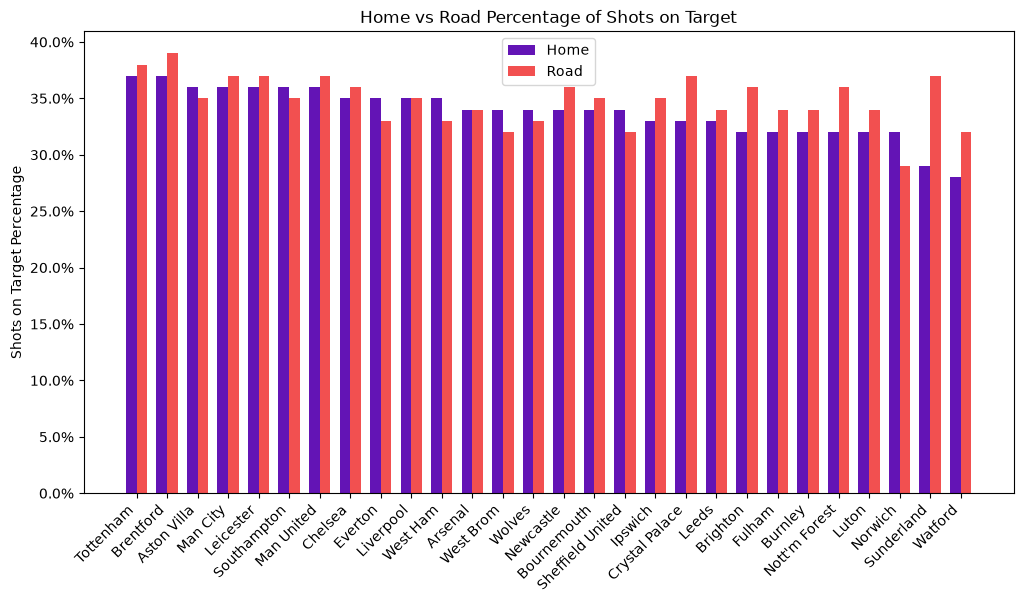

In [10]:
sot = sot.sort_values(
    "Percent SOT Home",
    ascending=False
).reset_index(drop=True)

x = np.arange(len(sot))
width = 0.35

fig, ax = plt.subplots(figsize=(12,6))

ax.bar(x - width/2, sot["Percent SOT Home"], width, label = "Home", color = "#6314b5")
ax.bar(x + width/2, sot["Percent SOT Away"], width, label = "Road", color = "#f25050")

ax.set_xticks(x)
ax.set_xticklabels(sot["Team"], rotation=45, ha="right")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylabel("Shots on Target Percentage")
ax.set_title("Home vs Road Percentage of Shots on Target")
ax.legend()

plt.tight_layout
plt.show()

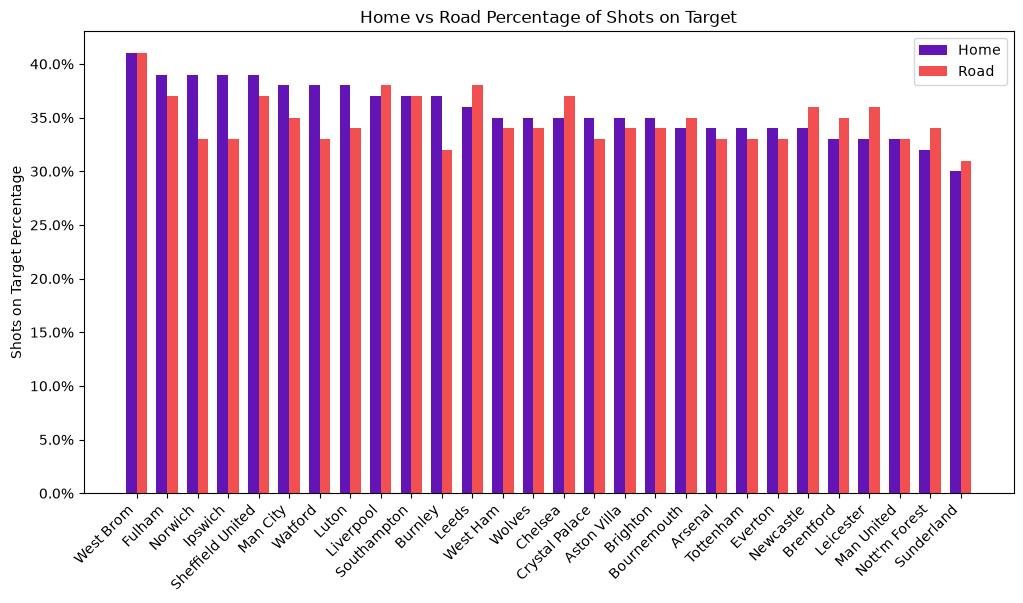

In [12]:
sot_against = sot_against.sort_values(
    "Percent SOT Allowed Home",
    ascending=False
).reset_index(drop=True)

x = np.arange(len(sot_against))
width = 0.35

fig, ax = plt.subplots(figsize=(12,6))

ax.bar(x - width/2, sot_against["Percent SOT Allowed Home"], width, label = "Home", color = "#6314b5")
ax.bar(x + width/2, sot_against["Percent SOT Allowed Away"], width, label = "Road", color = "#f25050")

ax.set_xticks(x)
ax.set_xticklabels(sot_against["Team"], rotation=45, ha="right")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylabel("Shots on Target Percentage")
ax.set_title("Home vs Road Percentage of Shots on Target")
ax.legend()

plt.tight_layout
plt.show()